# Exercise 1: CIFAR-10 Classification with a Non-Deep Learning Model 

In [11]:
import numpy as np
from tensorflow.keras.datasets import cifar10

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
print("Training data shape:", X_train.shape, "Labels shape:",
y_train.shape)
print("Test data shape:", X_test.shape, "Labels shape:", y_test.shape)
# Print the first 5 training labels
print("First 5 training labels:", y_train[:5].ravel())

Training data shape: (50000, 32, 32, 3) Labels shape: (50000, 1)
Test data shape: (10000, 32, 32, 3) Labels shape: (10000, 1)
First 5 training labels: [6 9 9 4 1]


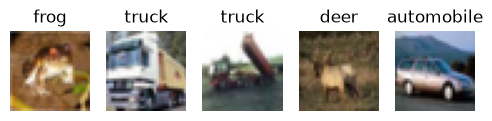

In [12]:
import matplotlib.pyplot as plt

# Define the class names for reference
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

# Plot a grid of 5 sample images from the training set
plt.figure(figsize=(6,2))
for i in range(5):
  plt.subplot(1, 5, i+1)
  plt.imshow(X_train[i])
  plt.title(class_names[int(y_train[i, 0])])
  plt.axis('off') # Hide axes ticks
plt.show()

In [13]:
# Convert images from [0,255] to [0,1] for numerical stability
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Flatten the images into 1D vectors

X_train_flat = X_train.reshape(X_train.shape[0], -1)
# shape becomes (50000, 3072)

X_test_flat = X_test.reshape(X_test.shape[0], -1)
# shape becomes (10000, 3072)

# Also flatten the label arrays from shape (N,1) to (N,) for use in scikit-learn
y_train_flat = y_train.ravel()

y_test_flat = y_test.ravel()

print("After flattening: ", X_train_flat.shape, y_train_flat.shape)

After flattening:  (50000, 3072) (50000,)


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Initialize Random Forest
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
# Train the model (this might take a few minutes)
rf_clf.fit(X_train_flat, y_train_flat)

# Make predictions on the test set
y_pred_rf = rf_clf.predict(X_test_flat)
# Calculate accuracy
acc_rf = accuracy_score(y_test_flat, y_pred_rf)
print(f"Random Forest test accuracy: {acc_rf:.4f}")

cm_rf = confusion_matrix(y_test_flat, y_pred_rf)
print("Confusion matrix:\n", cm_rf)

Random Forest test accuracy: 0.4654
Confusion matrix:
 [[560  37  61  20  30  21  19  28 165  59]
 [ 31 542  12  38  21  34  45  36  66 175]
 [ 99  36 334  83 139  66 122  55  35  31]
 [ 55  46  74 281  89 173 134  60  23  65]
 [ 54  21 139  61 382  44 159  93  26  21]
 [ 31  27  93 167  74 399  77  73  26  33]
 [ 13  30  86  78 101  54 566  32   6  34]
 [ 46  45  54  59 104  83  36 452  23  98]
 [ 89  85  18  32  16  40   8  22 614  76]
 [ 50 177  18  37  21  23  26  44  80 524]]


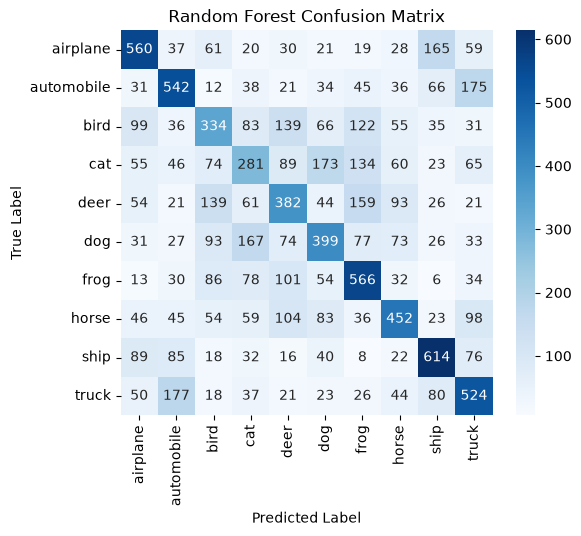

In [15]:
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues",
xticklabels=class_names, yticklabels=class_names)
plt.title("Random Forest Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()